# Feature Important
* Library 
* Load Data 
* Label Encoder
1.	Decision Tree
2.	Random Forest
3.	Gradient Boosting
4.	Permutation Importance
5.	Mutual Information
6.	SHAP (با مدل درختی)
7.	Chi2 (کای اسکوئر)
8.	Cramér's V
* Result

# Library

In [17]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.feature_selection import chi2
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
import shap
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt
import seaborn as sns

# Load data

In [18]:
def load_data(data):
    columns = ["class", "cap-shape", "cap-surface", "cap-color", "bruises",
               "odor", "gill-attachment", "gill-spacing", "gill-size", "gill-color",
               "stalk-shape", "stalk-root", "stalk-surface-above-ring", 
               "stalk-surface-below-ring", "stalk-color-above-ring",
               "stalk-color-below-ring", "veil-type", "veil-color", 
               "ring-number", "ring-type",
               "spore-print-color", "population", "habitat"]

    dataset = pd.read_csv(data, header=None, names=columns)
    return dataset

# Encoder 

In [19]:
def label_encoder(dataset):
    # حالت 1
    # le = LabelEncoder()

    # for col in dataset.columns:
    #     dataset[col] = le.fit_transform(dataset[col])

    # Label Encoding تمام ستون‌ها
    dataset_encoded = dataset.apply(LabelEncoder().fit_transform)

    X = dataset_encoded.drop('class', axis=1)
    y = dataset_encoded['class']

    return X, y

# Decision Tree

In [20]:
def decision_tree(X, y):
    dt = DecisionTreeClassifier(random_state=42)
    dt.fit(X, y)
    dt_importance = dt.feature_importances_
    dt_df = pd.DataFrame({'Feature': X.columns, 'Importance': dt_importance})
    dt_df_sorted = dt_df.sort_values(by='Importance', ascending=False).reset_index(drop=True)
    return dt_df_sorted

def decision_tree_chart(dt_df_sorted):
    plt.figure(figsize=(10,8))
    sns.barplot(x='Importance', y='Feature', data=dt_df_sorted)
    plt.title("Feature Importance based on Decision Tree")
    plt.show()

# Random Forest

In [21]:
def random_forest(X, y):
    rf = RandomForestClassifier(random_state=42)
    rf.fit(X, y)
    rf_importance = rf.feature_importances_
    rf_df = pd.DataFrame({'Feature': X.columns, 'Importance': rf_importance})
    rf_df_sorted = rf_df.sort_values(by='Importance', ascending=False).reset_index(drop=True)
    return rf_df_sorted, rf  # برگردوندن مدل برای SHAP

def random_forest_chart(rf_df_sorted):
    plt.figure(figsize=(10,8))
    sns.barplot(x='Importance', y='Feature', data=rf_df_sorted)
    plt.title("Feature Importance based on Random Forest")
    plt.show()

# Gradient Boosting

In [22]:
def gradient_boosting(X, y):
    gb = GradientBoostingClassifier(random_state=42)
    gb.fit(X, y)
    gb_importance = gb.feature_importances_
    gb_df = pd.DataFrame({'Feature': X.columns, 'Importance': gb_importance})
    gb_df_sorted = gb_df.sort_values(by='Importance', ascending=False).reset_index(drop=True)
    return gb_df_sorted

def gradient_boosting_chart(gb_df_sorted):
    plt.figure(figsize=(10,8))
    sns.barplot(x='Importance', y='Feature', data=gb_df_sorted)
    plt.title("Feature Importance based on Gradient Boosting")
    plt.show()

# Permutation

In [23]:
def permutation_importance_score(X, y):  # ✅ اسم تابع تغییر کرد
    rf = RandomForestClassifier(random_state=42)
    rf.fit(X, y)  # ✅ حتماً باید مدل آموزش ببینه
    perm = permutation_importance(rf, X, y, n_repeats=10, random_state=42)
    perm_df = pd.DataFrame({'Feature': X.columns, 'Importance': perm.importances_mean})
    perm_df_sorted = perm_df.sort_values(by='Importance', ascending=False).reset_index(drop=True)
    return perm_df_sorted

def permutation_chart(perm_df_sorted):  # ✅ اسم تابع تغییر کرد
    plt.figure(figsize=(10,8))
    sns.barplot(x='Importance', y='Feature', data=perm_df_sorted)
    plt.title("Feature Importance based on Permutation Importance")
    plt.show()

# Mutual

In [24]:
def mutual_info(X, y):  # ✅ اسم تابع تغییر کرد
    mi_scores = mutual_info_classif(X, y)
    mi_df = pd.DataFrame({'Feature': X.columns, 'MI Score': mi_scores})
    mi_df_sorted = mi_df.sort_values(by='MI Score', ascending=False).reset_index(drop=True)
    return mi_df_sorted

def mutual_info_chart(mi_df_sorted):  # ✅ اسم تابع تغییر کرد
    plt.figure(figsize=(10,8))
    sns.barplot(x='MI Score', y='Feature', data=mi_df_sorted)
    plt.title("Feature Importance based on Mutual Information")
    plt.show()

# Shap: Tree Explainer

In [25]:
def shap_tree_explainer(X, y, rf_model):  # ✅ مدل آموزش دیده رو دریافت می‌کنه
    explainer = shap.TreeExplainer(rf_model)
    shap_values = explainer.shap_values(X)
    
    # برای classification هدف
    if len(shap_values.shape) == 3:
        shap_importance = np.abs(shap_values[:, :, 1]).mean(axis=0)
    else:
        shap_importance = np.abs(shap_values).mean(axis=0)
    
    shap_df = pd.DataFrame({'Feature': X.columns, 'Importance': shap_importance})
    shap_df_sorted = shap_df.sort_values(by='Importance', ascending=False).reset_index(drop=True)
    return shap_df_sorted

def shap_chart(shap_df_sorted):
    plt.figure(figsize=(10,8))
    sns.barplot(x='Importance', y='Feature', data=shap_df_sorted)
    plt.title("Feature Importance based on SHAP")
    plt.show()

# Chi2

In [26]:
def chi2_score(X, y):
    chi_scores, p_values = chi2(X, y)
    chi_df = pd.DataFrame({'Feature': X.columns, 'Chi2 Score': chi_scores, 'p-value': p_values})
    chi_df_sorted = chi_df.sort_values(by='Chi2 Score', ascending=False).reset_index(drop=True)
    return chi_df_sorted

def chi2_chart(chi_df_sorted):
    plt.figure(figsize=(10,8))
    sns.barplot(x='Chi2 Score', y='Feature', data=chi_df_sorted)
    plt.title("Feature Importance based on Chi2 Score")
    plt.show()

# Cramers

In [27]:
def cramers(dataset):
    def cramers_v(x, y):
        contingency_table = pd.crosstab(x, y)
        chi2_val = chi2_contingency(contingency_table)[0]
        n = contingency_table.sum().sum()
        r, k = contingency_table.shape
        return np.sqrt(chi2_val / (n * (min(k-1, r-1))))

    cramers_results = []
    for col in dataset.columns:
        if col != 'class':
            score = cramers_v(dataset[col], dataset['class'])
            cramers_results.append((col, score))

    cramers_df = pd.DataFrame(cramers_results, columns=['Feature', "Cramers V"])
    cramers_df_sorted = cramers_df.sort_values(by="Cramers V", ascending=False).reset_index(drop=True)
    return cramers_df_sorted

def cramers_chart(cramers_df_sorted):
    plt.figure(figsize=(10,8))
    sns.barplot(x='Cramers V', y='Feature', data=cramers_df_sorted)
    plt.title("Feature Importance based on Cramer's V")
    plt.show()

# Result chart

In [28]:
def plot_all_features_top_n(chi_df_sorted, mi_df_sorted, dt_df_sorted, 
                           rf_df_sorted, gb_df_sorted, perm_df_sorted, 
                           cramers_df_sorted, shap_df_sorted, top_n=5):
    fig, axs = plt.subplots(4, 2, figsize=(18, 20))
    axs = axs.flatten()

    # Decision Tree
    sns.barplot(x='Importance', y='Feature', data=dt_df_sorted.head(top_n), ax=axs[2])
    axs[2].set_title("Top Features - Decision Tree")

    # Random Forest
    sns.barplot(x='Importance', y='Feature', data=rf_df_sorted.head(top_n), ax=axs[3])
    axs[3].set_title("Top Features - Random Forest")

    # Gradient Boosting
    sns.barplot(x='Importance', y='Feature', data=gb_df_sorted.head(top_n), ax=axs[4])
    axs[4].set_title("Top Features - Gradient Boosting")

    # Permutation Importance
    sns.barplot(x='Importance', y='Feature', data=perm_df_sorted.head(top_n), ax=axs[5])
    axs[5].set_title("Top Features - Permutation Importance")

    # Mutual Information
    sns.barplot(x='MI Score', y='Feature', data=mi_df_sorted.head(top_n), ax=axs[1])
    axs[1].set_title("Top Features - Mutual Information")

    # SHAP
    sns.barplot(x='Importance', y='Feature', data=shap_df_sorted.head(top_n), ax=axs[7])
    axs[7].set_title("Top Features - SHAP")

    # Chi2
    sns.barplot(x='Chi2 Score', y='Feature', data=chi_df_sorted.head(top_n), ax=axs[0])
    axs[0].set_title("Top Features - Chi2")

    # Cramér's V
    sns.barplot(x='Cramers V', y='Feature', data=cramers_df_sorted.head(top_n), ax=axs[6])
    axs[6].set_title("Top Features - Cramer's V")

    plt.tight_layout()
    plt.show()

# Result

In [29]:
data = r"Dataset\Mushroom\agaricus-lepiota.data"
dataset = load_data(data)
X, y = label_encoder(dataset)

In [30]:
# محاسبه اهمیت ویژگی‌ها با روش‌های مختلف
dt_df_sorted = decision_tree(X, y)
rf_df_sorted, rf_model = random_forest(X, y)  
gb_df_sorted = gradient_boosting(X, y)
chi_df_sorted = chi2_score(X, y)  
mi_df_sorted = mutual_info(X, y)  
perm_df_sorted = permutation_importance_score(X, y)  
shap_df_sorted = shap_tree_explainer(X, y, rf_model)  
cramers_df_sorted = cramers(dataset)

C:\Users\Asus\AppData\Local\Temp\ipykernel_167516\3059861371.py:7: RuntimeWarning: invalid value encountered in divide
  return np.sqrt(chi2_val / (n * (min(k-1, r-1))))


In [31]:
# نمایش نمودارهای تکی
# decision_tree_chart(dt_df_sorted)
# random_forest_chart(rf_df_sorted)
# gradient_boosting_chart(gb_df_sorted)
# chi2_chart(chi_df_sorted)
# mutual_info_chart(mi_df_sorted)  # ✅ اسم درست
# permutation_chart(perm_df_sorted)  # ✅ اسم درست
# shap_chart(shap_df_sorted)
# cramers_chart(cramers_df_sorted)

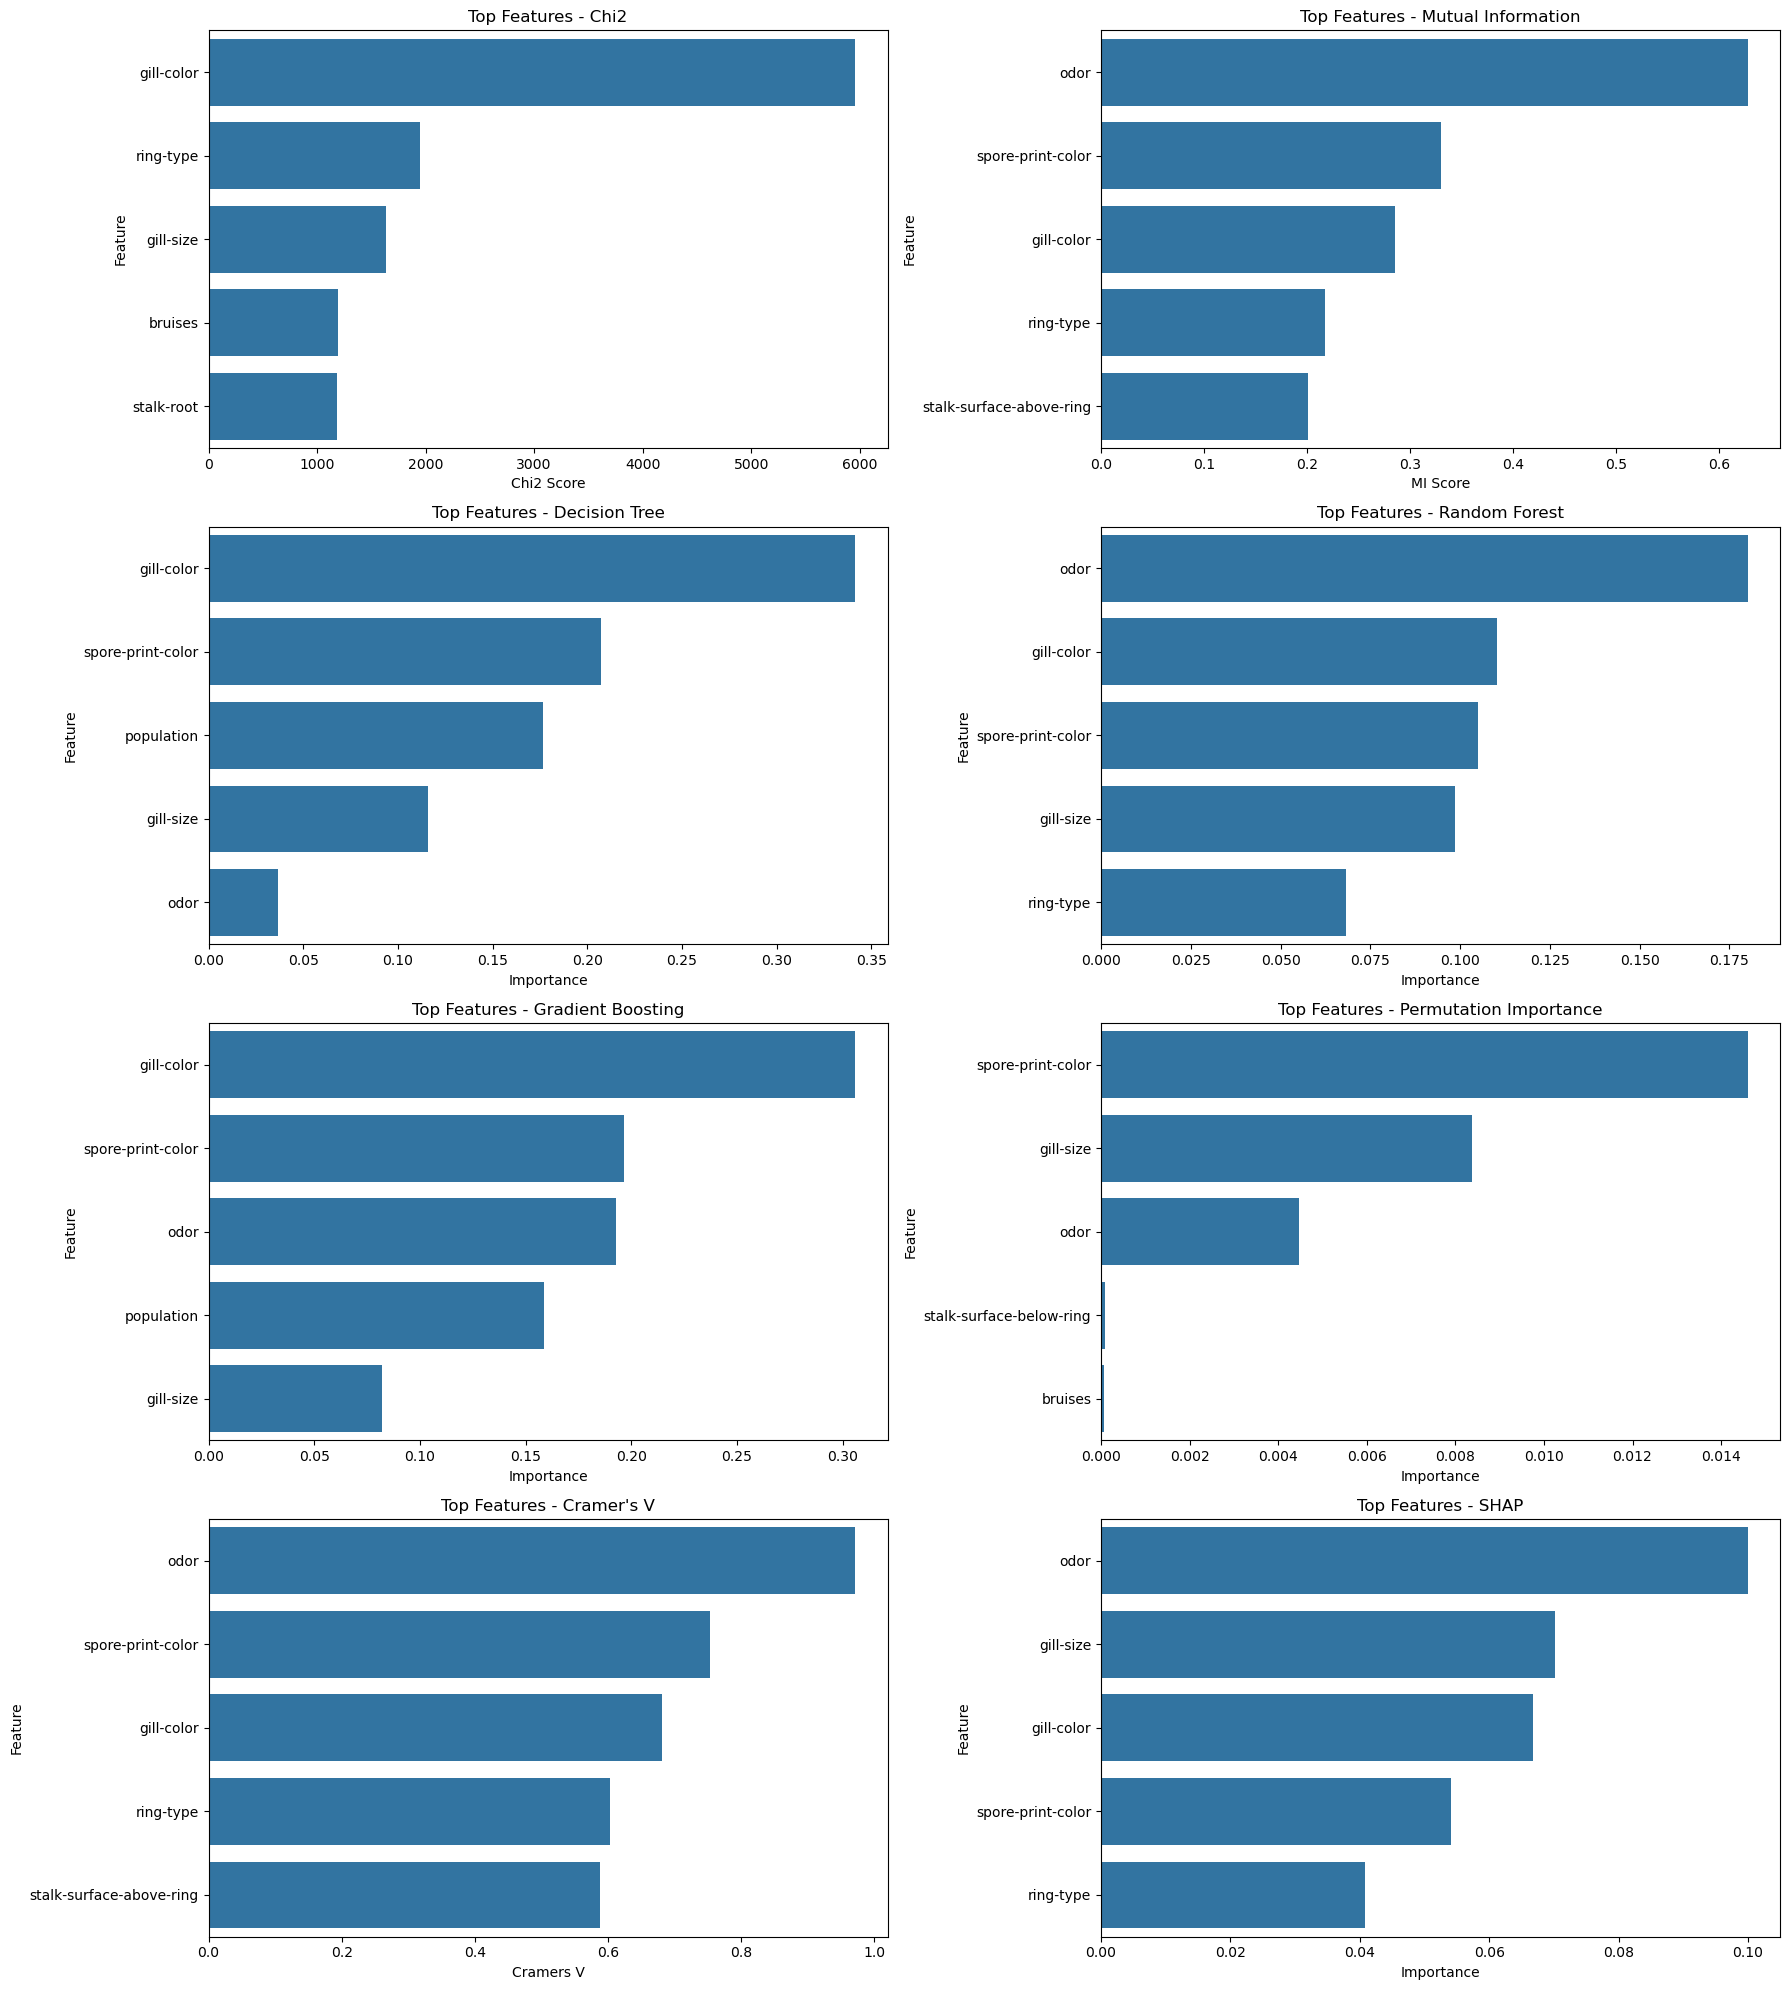

In [32]:
# نمایش نمودارهای ترکیبی
plot_all_features_top_n(chi_df_sorted, mi_df_sorted, dt_df_sorted, 
                       rf_df_sorted, gb_df_sorted, perm_df_sorted, 
                       cramers_df_sorted, shap_df_sorted, top_n=5)

| Summary                            | Value |
|-----------------------------------|-------|
| 1. odor                            | 7     |
| 2. spore – print – color           | 7     |
| 3. gill – size                     | 6     |
| 4. gill – color                    | 6     |
| 5. ring – type                     | 5     |
| 6. population                      | 2     |
| 7. Stalk – surface – above – ring  | 2     |
| 8. bruises                         | 1     |
| 9. Stalk – root                    | 1     |